# 1. Import Libraries and Load Dataset

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("/kaggle/input/datasets/decqno/insurance/insurance.csv")
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# 2. Data Preprocessing

## 2.1 Handling Missing Values

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

## 2.2 Encoding

In [7]:
df = pd.get_dummies (
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


## 2.3 Splitting Dataset

In [8]:
X = df.drop("charges", axis=1)
y = df["charges"]
print(X.shape, y.shape)

(1338, 8) (1338,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
560,46,19.95,2,0,0,1,0,0
1285,47,24.32,0,0,0,0,0,0
1142,52,24.86,0,0,0,0,1,0
969,39,34.32,5,0,0,0,1,0
486,54,21.47,3,0,0,1,0,0


In [10]:
X_test.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
764,45,25.175,2,0,0,0,0,0
887,36,30.020,0,0,0,1,0,0
890,64,26.885,0,0,1,1,0,0
1293,46,25.745,3,1,0,1,0,0
259,19,31.920,0,1,1,1,0,0


In [11]:
y_train.head()

560      9193.83850
1285     8534.67180
1142    27117.99378
969      8596.82780
486     12475.35130
Name: charges, dtype: float64

In [12]:
y_test.head()

764      9095.06825
887      5272.17580
890     29330.98315
1293     9301.89355
259     33750.29180
Name: charges, dtype: float64

## 2.4 Scaling

In [13]:
scale = StandardScaler()

X_train[["age", "bmi", "children"]] = scale.fit_transform(
    X_train[["age", "bmi", "children"]]
)

X_test[["age", "bmi", "children"]] = scale.transform(
    X_test[["age", "bmi", "children"]]
)

X_train.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
560,0.472227,-1.756525,0.734336,0,0,1,0,0
1285,0.543313,-1.033082,-0.911192,0,0,0,0,0
1142,0.898745,-0.943687,-0.911192,0,0,0,1,0
969,-0.025379,0.622393,3.202629,0,0,0,1,0
486,1.040918,-1.504893,1.557100,0,0,1,0,0


In [14]:
X_train[["age", "bmi", "children"]].mean()

age        -1.992176e-16
bmi        -4.648410e-17
children   -2.324205e-17
dtype: float64

In [15]:
X_train[["age", "bmi", "children"]].std()

age         1.000468
bmi         1.000468
children    1.000468
dtype: float64

# 3. Model Training

In [16]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [17]:
y_pred = model.predict(X_test)

y_pred

array([ 8969.55027444,  7068.74744287, 36858.41091155,  9454.67850053,
       26973.17345656, 10864.11316424,   170.28084136, 16903.45028662,
        1092.43093614, 11218.34318352, 28101.68455267,  9377.73460205,
        5263.0595179 , 38416.04221107, 40255.82339284, 37098.25353123,
       15240.39392306, 35912.88264434,  9112.52398703, 31461.92108909,
        3847.68845883, 10130.12001517,  2370.54189389,  7140.21550828,
       11301.76782638, 12961.65366224, 14509.47251876,  6159.8976107 ,
        9963.85857263,  2177.85718217,  9115.93673493, 13073.68932159,
        4561.82376202,  3408.20756033,  4459.81359745, 13032.06505076,
        1979.99357292,  8813.28303302, 33271.29124448, 32585.51583927,
        3908.76090964,  4326.10774721, 14142.81326533, 11423.45494846,
        8774.13955311, 12097.28051001,  5281.57353499,  3150.5596042 ,
       35494.46461214,  9150.1124786 , 15836.84575621,  2343.57470069,
       12364.78414194,  1482.29488266, 13389.06105161, 12573.57395972,
      

In [18]:
df_comparison = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
df_comparison.head(10)

,Actual,Predicted
764,9095.06825,8969.550274
887,5272.17580,7068.747443
890,29330.98315,36858.410912
1293,9301.89355,9454.678501
259,33750.29180,26973.173457
1312,4536.25900,10864.113164
899,2117.33885,170.280841
752,14210.53595,16903.450287
1286,3732.62510,1092.430936
707,10264.44210,11218.343184


# 4. Model Evaluation

In [19]:
# For training vs testing performance comparison
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [20]:
train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

print(f"Train MAE: {train_mae}")
print(f"Test MAE: {test_mae}")

Train MAE: 4208.234572492226
Test MAE: 4181.194473753652


In [21]:
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f"Train MSE: {train_mse}")
print(f"Test MSE: {test_mse}")

Train MSE: 37277681.70201866
Test MSE: 33596915.85136148


In [29]:
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Train R2: {train_r2}")
print(f"Test R2: {test_r2}")

Train R2: 0.7417255854683333
Test R2: 0.7835929767120722


In [31]:
evaluation = pd.DataFrame({
    "Metric": ["Mean Absolute Error", "Mean Squared Error", "R-Squared"],
    "Training": [round(train_mae, 2), round(train_mse, 2), round(train_r2, 2)],
    "Testing": [round(test_mae, 2), round(test_mse, 2), round(test_r2, 2)]
})

evaluation

,Metric,Training,Testing
0,Mean Absolute Error,4208.23,4181.19
1,Mean Squared Error,37277681.70,33596915.85
2,R-Squared,0.74,0.78


# 5. Visualizations

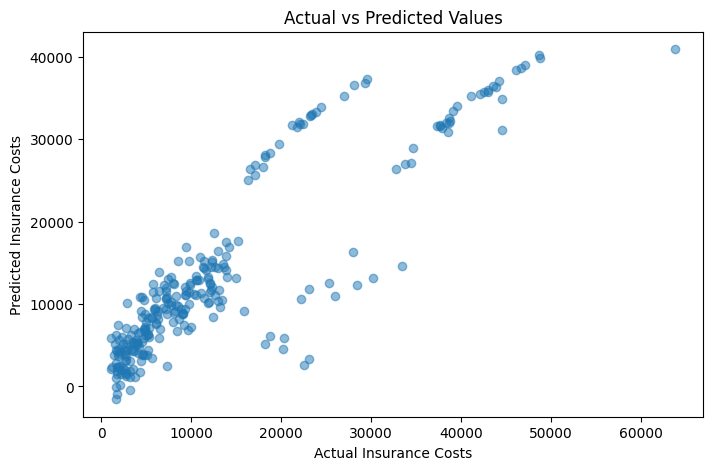

In [24]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_test_pred, alpha=0.5)

plt.xlabel("Actual Insurance Costs")
plt.ylabel("Predicted Insurance Costs")
plt.title("Actual vs Predicted Values")

plt.show()

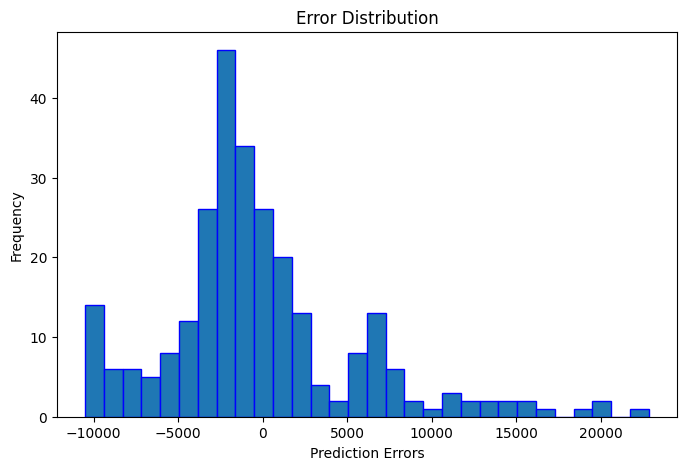

In [25]:
residual = y_test - y_test_pred

plt.figure(figsize=(8, 5))
plt.hist(residual, bins=30, edgecolor="blue")

plt.xlabel("Prediction Errors")
plt.ylabel("Frequency")
plt.title("Error Distribution")

plt.show()

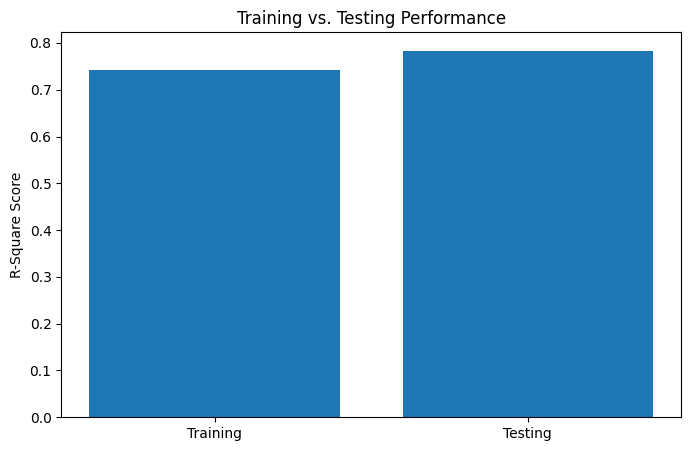

In [26]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Training", "Testing"],
    [train_r2, test_r2]
)

plt.ylabel("R-Square Score")
plt.title("Training vs. Testing Performance")

plt.show()